In [1]:
import pandas as pd
import os
import seaborn as sns
import matplotlib.pyplot as plt
from scipy import stats
import numpy as np
import smarts_cerebellum.globals as gl

obs = pd.read_csv(os.path.join(gl.baseDir, 'MNISymC_FaMap', 'summary_MNISymC_Nettekoven_MADS_FaMap.tsv'), sep = '\t')
obs = obs[obs.hemisphere == 'L']
obs = obs.sort_values('Week')

lme = pd.read_csv(os.path.join(gl.baseDir, 'lme', 'patients_MNISymC_FaMap_Nettekoven_MADS_lme.tsv'), sep = '\t')
lme['region_bilat'] = lme['regionname'].astype(str).str[-1]
lme = lme.sort_values('Week')

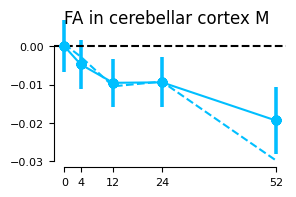

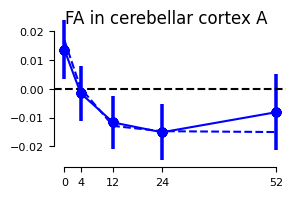

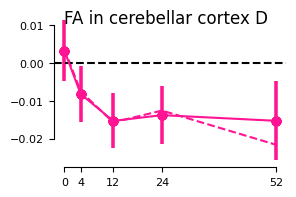

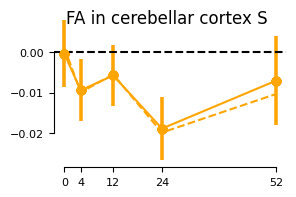

In [2]:
colours = ['deepskyblue', 'blue', 'deeppink', 'orange']
for r,roi in enumerate(['M', 'A', 'D', 'S']):
    # show the lme-lme plot
    fig, ax = plt.subplots(figsize = (3,2))

    lme_roi = lme[lme.regionname.str.startswith(roi)]
    obs_roi = obs[(obs.regionname.str.contains(roi))&(obs.hemisphere == 'L')]
    obs_roi = obs_roi.groupby(['Week']).agg({'asymmetry_index': 'mean'}).reset_index()
    
    ax.errorbar(x = lme_roi['Week'], y = lme_roi['beta'], yerr = lme_roi['se'], fmt = '-o', color = colours[r])
    ax.plot(obs_roi['Week'], obs_roi['asymmetry_index'], color = colours[r], linestyle = '--')


    ax.set_xticks(gl.weeks)
    ax.axhline(y = 0, linestyle = '--', color = 'k')

    fig.suptitle(f"FA in cerebellar cortex {roi}", y = .9)
    sns.despine(trim = True)
    plt.show()